In [1]:
print("Welcome to SupplySense!")
print("Starting Machine Learning development.")

Welcome to SupplySense!
Starting Machine Learning development.


In [3]:
import pandas as pd

df = pd.read_csv('/content/data.csv', encoding='latin1')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [6]:
df.shape
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [7]:
print("Cancelled invoices:",
      df['InvoiceNo'].astype(str).str.startswith('C').sum())

print("Non-positive quantities:",
      (df['Quantity'] <= 0).sum())

print("Non-positive prices:",
      (df['UnitPrice'] <= 0).sum())

Cancelled invoices: 9288
Non-positive quantities: 10624
Non-positive prices: 2517


In [8]:
# Keep a copy of the original dataset
df_raw = df.copy()

# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove invalid quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Convert InvoiceDate into datetime format
df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    dayfirst=True,
    errors='coerce'
)

# Remove rows with invalid dates
df = df.dropna(subset=['InvoiceDate'])

print("Shape after cleaning:", df.shape)

Shape after cleaning: (227703, 8)


In [9]:
# Group transactions by date and calculate total daily demand
daily = df.groupby(df['InvoiceDate'].dt.date)['Quantity'].sum().reset_index()

# Rename columns
daily.columns = ['Date', 'Demand']

# Convert Date column into datetime format
daily['Date'] = pd.to_datetime(daily['Date'])

# Include dates with no sales and assign demand as 0
daily = daily.set_index('Date').asfreq('D', fill_value=0).reset_index()

print(daily.head())
print("Total days:", len(daily))

        Date  Demand
0 2010-01-12   26919
1 2010-01-13       0
2 2010-01-14       0
3 2010-01-15       0
4 2010-01-16       0
Total days: 698


In [10]:
# Start again from the original dataset
df = df_raw.copy()

# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove invalid quantities and prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Correctly interpret dates as month/day/year
df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    dayfirst=False,
    errors='coerce'
)

# Remove invalid dates
df = df.dropna(subset=['InvoiceDate'])

# Aggregate daily demand
daily = df.groupby(df['InvoiceDate'].dt.date)['Quantity'].sum().reset_index()
daily.columns = ['Date', 'Demand']

daily['Date'] = pd.to_datetime(daily['Date'])

# Include missing calendar dates
daily = daily.set_index('Date').asfreq('D', fill_value=0).reset_index()

print(daily.head())
print("Total days:", len(daily))

        Date  Demand
0 2010-12-01   26919
1 2010-12-02   31329
2 2010-12-03   16199
3 2010-12-04       0
4 2010-12-05   16450
Total days: 374


In [11]:
# Extract month and day of the week
daily['Month'] = daily['Date'].dt.month
daily['DayOfWeek'] = daily['Date'].dt.dayofweek

# Demand from 7 days earlier
daily['Lag7'] = daily['Demand'].shift(7)

# Average demand of the previous 7 days
daily['Roll7'] = daily['Demand'].shift(1).rolling(window=7).mean()

print(daily.head(12))

         Date  Demand  Month  DayOfWeek     Lag7         Roll7
0  2010-12-01   26919     12          2      NaN           NaN
1  2010-12-02   31329     12          3      NaN           NaN
2  2010-12-03   16199     12          4      NaN           NaN
3  2010-12-04       0     12          5      NaN           NaN
4  2010-12-05   16450     12          6      NaN           NaN
5  2010-12-06   21795     12          0      NaN           NaN
6  2010-12-07   25220     12          1      NaN           NaN
7  2010-12-08   23117     12          2  26919.0  19701.714286
8  2010-12-09   19930     12          3  31329.0  19158.571429
9  2010-12-10   21097     12          4  16199.0  17530.142857
10 2010-12-11       0     12          5      0.0  18229.857143
11 2010-12-12   10603     12          6  16450.0  18229.857143


In [12]:
# Remove rows containing NaN values
data = daily.dropna().copy()

# Select input features
X = data[['Month', 'DayOfWeek', 'Lag7', 'Roll7']]

# Select target variable
y = data['Demand']

# Split data chronologically (80% training, 20% testing)
split = int(len(data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", list(X.columns))

Training rows: 293
Testing rows: 74
Features: ['Month', 'DayOfWeek', 'Lag7', 'Roll7']


In [13]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict demand for test data
lr_predictions = lr_model.predict(X_test)

print("Linear Regression training completed!")
print("Sample predictions:", lr_predictions[:5])

Linear Regression training completed!
Sample predictions: [30090.33874969 18901.80477447 22599.20796445 16310.52324374
  5457.28314229]


In [14]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict demand
rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed!")
print("Sample predictions:", rf_predictions[:5])

Random Forest training completed!
Sample predictions: [32073.83 20505.78 23064.84 16530.17     0.  ]


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate Linear Regression
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Display results
print("LINEAR REGRESSION")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

print("\nRANDOM FOREST")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

LINEAR REGRESSION
MAE: 8805.996101215158
RMSE: 12831.90430935688
R2 Score: 0.2543101000357525

RANDOM FOREST
MAE: 7316.616891891892
RMSE: 11702.246589027542
R2 Score: 0.3798246123584783


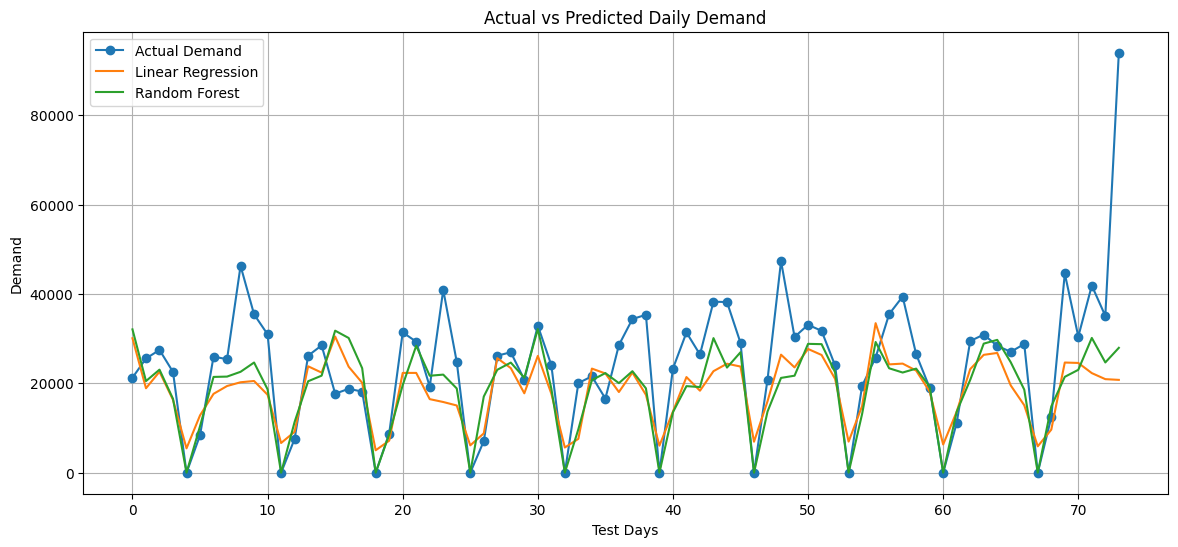

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(y_test.values, label='Actual Demand', marker='o')
plt.plot(lr_predictions, label='Linear Regression')
plt.plot(rf_predictions, label='Random Forest')

plt.title('Actual vs Predicted Daily Demand')
plt.xlabel('Test Days')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
# Start with the last 7 days of actual demand
history = list(daily['Demand'].tail(7))

future_predictions = []

# Generate predictions for the next 7 days
for i in range(7):

    next_date = daily['Date'].max() + pd.Timedelta(days=i+1)

    month = next_date.month
    day = next_date.dayofweek
    lag7 = history[-7]
    roll7 = np.mean(history[-7:])

    prediction = rf_model.predict(
        [[month, day, lag7, roll7]]
    )[0]

    prediction = max(0, prediction)

    future_predictions.append(prediction)
    history.append(prediction)

# Display forecast
forecast = pd.DataFrame({
    'Date': pd.date_range(
        start=daily['Date'].max() + pd.Timedelta(days=1),
        periods=7
    ),
    'Predicted_Demand': future_predictions
})

print(forecast)

        Date  Predicted_Demand
0 2011-12-10              0.00
1 2011-12-11          13999.43
2 2011-12-12          29248.60
3 2011-12-13          23369.40
4 2011-12-14          30188.16
5 2011-12-15          24831.90
6 2011-12-16          28368.52


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/

In [18]:
# Count transactions for each product
product_counts = df.groupby('StockCode').agg(
    Transaction_Count=('Quantity', 'count'),
    Total_Quantity_Sold=('Quantity', 'sum'),
    Product_Name=('Description', 'first')
).reset_index()

# Display the 10 most frequently purchased products
top_products = product_counts.sort_values(
    by='Transaction_Count',
    ascending=False
).head(10)

print(top_products)

     StockCode  Transaction_Count  Total_Quantity_Sold  \
3407    85123A               2265                37660   
3387    85099B               2112                48474   
1310     22423               2017                13879   
2670     47566               1706                18295   
175      20725               1595                19553   
3194     84879               1489                36461   
1109     22197               1426                56921   
1593     22720               1399                 7493   
439      21212               1370                36419   
177      20727               1328                12240   

                            Product_Name  
3407  WHITE HANGING HEART T-LIGHT HOLDER  
3387             JUMBO BAG RED RETROSPOT  
1310            REGENCY CAKESTAND 3 TIER  
2670                       PARTY BUNTING  
175              LUNCH BAG RED RETROSPOT  
3194       ASSORTED COLOUR BIRD ORNAMENT  
1109                SMALL POPCORN HOLDER  
1593   SET OF 3 C

In [19]:
# Select our first product
selected_product = '85123A'

# Filter transactions for this product
product_df = df[
    df['StockCode'].astype(str) == selected_product
].copy()

# Calculate daily demand
product_daily = product_df.groupby(
    product_df['InvoiceDate'].dt.normalize()
)['Quantity'].sum()

# Include every calendar date
all_dates = pd.date_range(
    start=df['InvoiceDate'].min().normalize(),
    end=df['InvoiceDate'].max().normalize(),
    freq='D'
)

product_daily = product_daily.reindex(all_dates, fill_value=0)

# Convert into a DataFrame
product_daily = product_daily.rename_axis('Date').reset_index()
product_daily.columns = ['Date', 'Demand']

print(product_daily.head(10))
print("Total days:", len(product_daily))
print("Total units sold:", product_daily['Demand'].sum())

        Date  Demand
0 2010-12-01     454
1 2010-12-02     309
2 2010-12-03      25
3 2010-12-04       0
4 2010-12-05     198
5 2010-12-06     161
6 2010-12-07     331
7 2010-12-08     151
8 2010-12-09     195
9 2010-12-10     165
Total days: 374
Total units sold: 37660


In [20]:
# Extract month and weekday
product_daily['Month'] = product_daily['Date'].dt.month
product_daily['DayOfWeek'] = product_daily['Date'].dt.dayofweek

# Demand from 7 days earlier
product_daily['Lag7'] = product_daily['Demand'].shift(7)

# Average demand over the previous 7 days
product_daily['Roll7'] = (
    product_daily['Demand'].shift(1).rolling(window=7).mean()
)

print(product_daily.head(12))

         Date  Demand  Month  DayOfWeek   Lag7       Roll7
0  2010-12-01     454     12          2    NaN         NaN
1  2010-12-02     309     12          3    NaN         NaN
2  2010-12-03      25     12          4    NaN         NaN
3  2010-12-04       0     12          5    NaN         NaN
4  2010-12-05     198     12          6    NaN         NaN
5  2010-12-06     161     12          0    NaN         NaN
6  2010-12-07     331     12          1    NaN         NaN
7  2010-12-08     151     12          2  454.0  211.142857
8  2010-12-09     195     12          3  309.0  167.857143
9  2010-12-10     165     12          4   25.0  151.571429
10 2010-12-11       0     12          5    0.0  171.571429
11 2010-12-12      42     12          6  198.0  171.571429


In [21]:
# Remove rows with missing feature values
product_data = product_daily.dropna().copy()

# Select input features
X_product = product_data[
    ['Month', 'DayOfWeek', 'Lag7', 'Roll7']
]

# Select target variable
y_product = product_data['Demand']

# Split chronologically
split = int(len(product_data) * 0.8)

X_train_product = X_product.iloc[:split]
X_test_product = X_product.iloc[split:]

y_train_product = y_product.iloc[:split]
y_test_product = y_product.iloc[split:]

print("Training rows:", len(X_train_product))
print("Testing rows:", len(X_test_product))

Training rows: 293
Testing rows: 74


In [22]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
product_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train using product-specific data
product_model.fit(X_train_product, y_train_product)

# Predict test data
product_predictions = product_model.predict(X_test_product)

print("Product-specific model training completed!")
print("Sample predictions:", product_predictions[:5])

Product-specific model training completed!
Sample predictions: [114.51  97.02 153.08  79.81   0.  ]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

product_mae = mean_absolute_error(y_test_product, product_predictions)
product_rmse = np.sqrt(mean_squared_error(y_test_product, product_predictions))
product_r2 = r2_score(y_test_product, product_predictions)

print("PRODUCT-SPECIFIC RANDOM FOREST")
print("MAE:", product_mae)
print("RMSE:", product_rmse)
print("R2 Score:", product_r2)

PRODUCT-SPECIFIC RANDOM FOREST
MAE: 83.36486486486487
RMSE: 166.90739388185423
R2 Score: -0.032572490663765


In [24]:
print("ACTUAL DEMAND STATISTICS")
print("Mean:", y_test_product.mean())
print("Median:", y_test_product.median())
print("Maximum:", y_test_product.max())
print("Zero-demand days:", (y_test_product == 0).sum())
print("Total test days:", len(y_test_product))

print("\nPREDICTED DEMAND STATISTICS")
print("Mean:", product_predictions.mean())
print("Minimum:", product_predictions.min())
print("Maximum:", product_predictions.max())

ACTUAL DEMAND STATISTICS
Mean: 104.6891891891892
Median: 70.0
Maximum: 1265
Zero-demand days: 10
Total test days: 74

PREDICTED DEMAND STATISTICS
Mean: 105.7191891891892
Minimum: 0.0
Maximum: 645.55


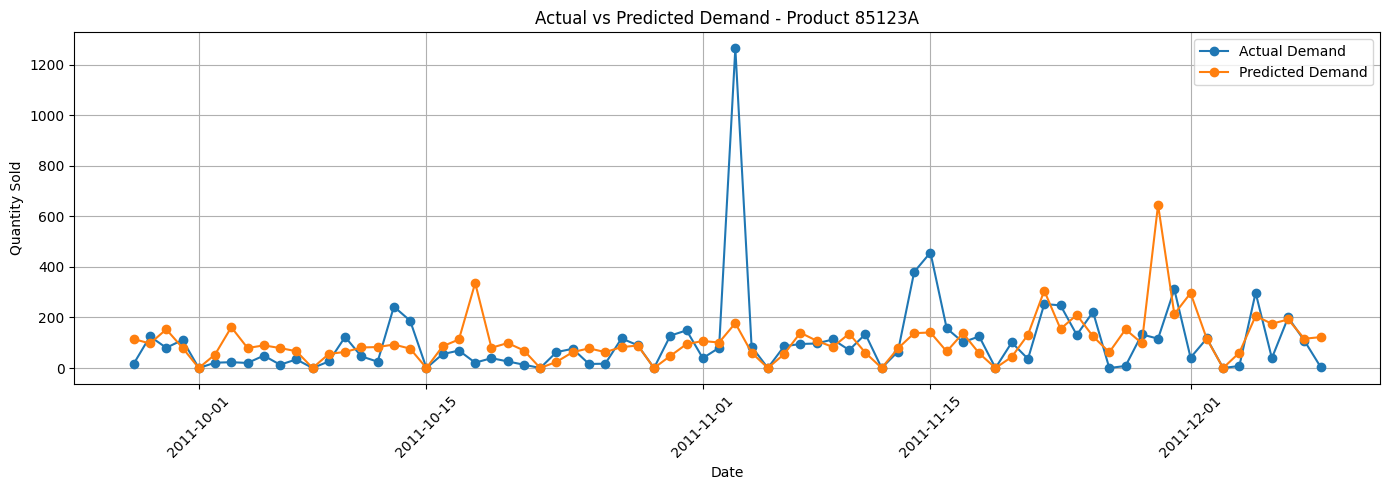

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    product_data['Date'].iloc[split:],
    y_test_product,
    label='Actual Demand',
    marker='o'
)

plt.plot(
    product_data['Date'].iloc[split:],
    product_predictions,
    label='Predicted Demand',
    marker='o'
)

plt.title('Actual vs Predicted Demand - Product 85123A')
plt.xlabel('Date')
plt.ylabel('Quantity Sold')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [26]:
improved_daily = product_daily.copy()

improved_daily['Month'] = improved_daily['Date'].dt.month
improved_daily['DayOfWeek'] = improved_daily['Date'].dt.dayofweek

improved_daily['Lag1'] = improved_daily['Demand'].shift(1)
improved_daily['Lag3'] = improved_daily['Demand'].shift(3)
improved_daily['Lag7'] = improved_daily['Demand'].shift(7)

improved_daily['Roll7'] = (
    improved_daily['Demand'].shift(1).rolling(7).mean()
)

improved_daily['Roll14'] = (
    improved_daily['Demand'].shift(1).rolling(14).mean()
)

improved_data = improved_daily.dropna().copy()

print("Improved dataset shape:", improved_data.shape)
print(improved_data.head())

Improved dataset shape: (360, 9)
         Date  Demand  Month  DayOfWeek   Lag7       Roll7   Lag1   Lag3  \
14 2010-12-15     112     12          2  151.0  153.571429  185.0   42.0   
15 2010-12-16     790     12          3  195.0  148.000000  112.0  337.0   
16 2010-12-17      58     12          4  165.0  233.000000  790.0  185.0   
17 2010-12-18       0     12          5    0.0  217.714286   58.0  112.0   
18 2010-12-19      42     12          6   42.0  217.714286    0.0  790.0   

        Roll14  
14  182.357143  
15  157.928571  
16  192.285714  
17  194.642857  
18  194.642857  


In [27]:
from sklearn.ensemble import RandomForestRegressor

# Select features and target
features = [
    'Month', 'DayOfWeek',
    'Lag1', 'Lag3', 'Lag7',
    'Roll7', 'Roll14'
]

X_improved = improved_data[features]
y_improved = improved_data['Demand']

# Chronological train-test split
split_improved = int(len(improved_data) * 0.8)

X_train_improved = X_improved.iloc[:split_improved]
X_test_improved = X_improved.iloc[split_improved:]

y_train_improved = y_improved.iloc[:split_improved]
y_test_improved = y_improved.iloc[split_improved:]

# Train model
improved_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

improved_model.fit(X_train_improved, y_train_improved)

# Predictions
improved_predictions = improved_model.predict(X_test_improved)

print("Improved model training completed!")
print("Training rows:", len(X_train_improved))
print("Testing rows:", len(X_test_improved))
print("Sample predictions:", improved_predictions[:5])

Improved model training completed!
Training rows: 288
Testing rows: 72
Sample predictions: [125.91795548  71.8645175    0.          59.83538069 139.19653731]


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

improved_mae = mean_absolute_error(
    y_test_improved, improved_predictions
)

improved_rmse = np.sqrt(
    mean_squared_error(y_test_improved, improved_predictions)
)

improved_r2 = r2_score(
    y_test_improved, improved_predictions
)

print("IMPROVED RANDOM FOREST")
print("MAE:", improved_mae)
print("RMSE:", improved_rmse)
print("R2 Score:", improved_r2)

IMPROVED RANDOM FOREST
MAE: 90.25268545254761
RMSE: 170.10906409589973
R2 Score: -0.04786387008869064


In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Original feature set
original_features = ['Month', 'DayOfWeek', 'Lag7', 'Roll7']

# Improved feature set
improved_features = [
    'Month', 'DayOfWeek', 'Lag1', 'Lag3',
    'Lag7', 'Roll7', 'Roll14'
]

# Same dataset and chronological split
split = int(len(improved_data) * 0.8)

train_data = improved_data.iloc[:split]
test_data = improved_data.iloc[split:]

y_train = train_data['Demand']
y_test = test_data['Demand']

# Original model
model_original = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model_original.fit(train_data[original_features], y_train)
pred_original = model_original.predict(test_data[original_features])

# Improved model
model_improved = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model_improved.fit(train_data[improved_features], y_train)
pred_improved = model_improved.predict(test_data[improved_features])

# Compare metrics
for name, predictions in [
    ("Original Model", pred_original),
    ("Improved Model", pred_improved)
]:
    print("\n", name)
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("R2:", r2_score(y_test, predictions))


 Original Model
MAE: 96.43388888888889
RMSE: 182.67514162213388
R2: -0.20839483793433633

 Improved Model
MAE: 93.32291666666667
RMSE: 172.6370053955537
R2: -0.07923928113819168


In [30]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

boost_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

boost_model.fit(
    train_data[improved_features],
    y_train
)

boost_predictions = boost_model.predict(
    test_data[improved_features]
)

print("GRADIENT BOOSTING MODEL")
print("MAE:", mean_absolute_error(y_test, boost_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, boost_predictions)))
print("R2:", r2_score(y_test, boost_predictions))

GRADIENT BOOSTING MODEL
MAE: 98.6692641151792
RMSE: 177.45396242986726
R2: -0.14030586628225494


In [31]:
print("DEMAND DISTRIBUTION")

print("\nDemand percentiles:")
print(product_daily['Demand'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

print("\nHighest demand days:")
print(
    product_daily.nlargest(10, 'Demand')[['Date', 'Demand']]
)

DEMAND DISTRIBUTION

Demand percentiles:
count     374.000000
mean      100.695187
std       223.737802
min         0.000000
25%        15.000000
50%        58.000000
75%       116.000000
90%       197.100000
95%       309.700000
99%       787.080000
max      3114.000000
Name: Demand, dtype: float64

Highest demand days:
          Date  Demand
41  2011-01-11    3114
138 2011-04-18    2102
337 2011-11-03    1265
15  2010-12-16     790
223 2011-07-12     786
176 2011-05-26     653
239 2011-07-28     490
349 2011-11-15     457
0   2010-12-01     454
155 2011-05-05     421


In [32]:
weekday_analysis = product_daily.copy()

weekday_analysis['DayOfWeek'] = (
    weekday_analysis['Date'].dt.day_name()
)

weekday_summary = weekday_analysis.groupby(
    'DayOfWeek'
)['Demand'].agg(
    ['mean', 'median', 'max', 'count']
)

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_summary = weekday_summary.reindex(weekday_order)

print(weekday_summary)

                 mean  median   max  count
DayOfWeek                                 
Monday     126.943396    66.0  2102     53
Tuesday    186.000000   110.0  3114     53
Wednesday  104.240741    81.5   454     54
Thursday   154.462963    91.5  1265     54
Friday      73.240741    49.0   334     54
Saturday     0.000000     0.0     0     53
Sunday      59.415094    47.0   198     53


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use demand from exactly 7 days earlier
demand_lookup = product_daily.set_index('Date')['Demand']

baseline_predictions = test_data['Date'].apply(
    lambda date: demand_lookup.get(
        date - pd.Timedelta(days=7), 0
    )
).values

print("WEEKLY SEASONAL NAIVE MODEL")
print("MAE:", mean_absolute_error(y_test, baseline_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, baseline_predictions)))
print("R2:", r2_score(y_test, baseline_predictions))

WEEKLY SEASONAL NAIVE MODEL
MAE: 98.20833333333333
RMSE: 220.16600428868315
R2: -0.7552964610585295


In [34]:
# Aggregate daily demand for every product
multi_product_daily = df.groupby(
    ['StockCode', df['InvoiceDate'].dt.normalize()]
)['Quantity'].sum().reset_index()

multi_product_daily.columns = [
    'StockCode', 'Date', 'Demand'
]

print("Total products:", multi_product_daily['StockCode'].nunique())
print("Total records:", len(multi_product_daily))
print(multi_product_daily.head())

Total products: 3922
Total records: 276148
  StockCode       Date  Demand
0     10002 2010-12-01      60
1     10002 2010-12-02       1
2     10002 2010-12-03       8
3     10002 2010-12-05       1
4     10002 2010-12-06      25


In [35]:
# Create a complete date range
all_dates = pd.date_range(
    start=multi_product_daily['Date'].min(),
    end=multi_product_daily['Date'].max(),
    freq='D'
)

# Create every product-date combination
all_combinations = pd.MultiIndex.from_product(
    [
        multi_product_daily['StockCode'].unique(),
        all_dates
    ],
    names=['StockCode', 'Date']
)

# Fill missing demand with zero
multi_product_daily = (
    multi_product_daily
    .set_index(['StockCode', 'Date'])
    .reindex(all_combinations, fill_value=0)
    .reset_index()
)

print("Updated dataset shape:", multi_product_daily.shape)
print("Total products:", multi_product_daily['StockCode'].nunique())
print(multi_product_daily.head(10))

Updated dataset shape: (1466828, 3)
Total products: 3922
  StockCode       Date  Demand
0     10002 2010-12-01      60
1     10002 2010-12-02       1
2     10002 2010-12-03       8
3     10002 2010-12-04       0
4     10002 2010-12-05       1
5     10002 2010-12-06      25
6     10002 2010-12-07       8
7     10002 2010-12-08      13
8     10002 2010-12-09      44
9     10002 2010-12-10      48


In [36]:
# Calendar features
multi_product_daily['Month'] = (
    multi_product_daily['Date'].dt.month
)

multi_product_daily['DayOfWeek'] = (
    multi_product_daily['Date'].dt.dayofweek
)

# Historical demand features for each product
grouped = multi_product_daily.groupby('StockCode')['Demand']

multi_product_daily['Lag1'] = grouped.shift(1)
multi_product_daily['Lag7'] = grouped.shift(7)

multi_product_daily['Roll7'] = grouped.transform(
    lambda x: x.shift(1).rolling(7).mean()
)

multi_product_daily['Roll14'] = grouped.transform(
    lambda x: x.shift(1).rolling(14).mean()
)

# Remove rows without sufficient historical data
multi_product_data = multi_product_daily.dropna().copy()

print("Feature creation completed!")
print("Final dataset shape:", multi_product_data.shape)
print("\nFeatures:")
print(multi_product_data.head())

Feature creation completed!
Final dataset shape: (1411920, 9)

Features:
   StockCode       Date  Demand  Month  DayOfWeek  Lag1  Lag7      Roll7  \
14     10002 2010-12-15       0     12          2   7.0  13.0  19.857143   
15     10002 2010-12-16       5     12          3   0.0  44.0  18.000000   
16     10002 2010-12-17       2     12          4   5.0  48.0  12.428571   
17     10002 2010-12-18       0     12          5   2.0   0.0   5.857143   
18     10002 2010-12-19       0     12          6   0.0   0.0   5.857143   

       Roll14  
14  17.285714  
15  13.000000  
16  13.285714  
17  12.857143  
18  12.857143  


In [37]:
# Sort records chronologically
multi_product_data = multi_product_data.sort_values(
    'Date'
).reset_index(drop=True)

# Find the 80% date cutoff
unique_dates = sorted(multi_product_data['Date'].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

# Split by date
train_data = multi_product_data[
    multi_product_data['Date'] < split_date
].copy()

test_data = multi_product_data[
    multi_product_data['Date'] >= split_date
].copy()

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)
print("Training ends:", train_data['Date'].max())
print("Testing starts:", test_data['Date'].min())
print("Products in training:", train_data['StockCode'].nunique())
print("Products in testing:", test_data['StockCode'].nunique())

Training data: (1129536, 9)
Testing data: (282384, 9)
Training ends: 2011-09-28 00:00:00
Testing starts: 2011-09-29 00:00:00
Products in training: 3922
Products in testing: 3922


In [38]:
from sklearn.preprocessing import LabelEncoder

product_encoder = LabelEncoder()

# Fit on all product identifiers
product_encoder.fit(multi_product_data['StockCode'])

# Encode product IDs
train_data['Product_ID'] = product_encoder.transform(
    train_data['StockCode']
)

test_data['Product_ID'] = product_encoder.transform(
    test_data['StockCode']
)

print("Product encoding completed!")
print("Unique encoded products:", len(product_encoder.classes_))
print(train_data[['StockCode', 'Product_ID']].head())

Product encoding completed!
Unique encoded products: 3922
  StockCode  Product_ID
0     10002           0
1     20735         182
2     71053        2729
3    71101E        2730
4     71143        2731


In [39]:
features = [
    'Product_ID',
    'Month',
    'DayOfWeek',
    'Lag1',
    'Lag7',
    'Roll7',
    'Roll14'
]

target = 'Demand'

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1129536, 7)
Testing features: (282384, 7)
Training target: (1129536,)
Testing target: (282384,)


In [40]:
from sklearn.ensemble import RandomForestRegressor

shared_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

shared_model.fit(X_train, y_train)

print("Shared multi-product model training completed!")

Shared multi-product model training completed!


In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

shared_predictions = shared_model.predict(X_test)

shared_mae = mean_absolute_error(y_test, shared_predictions)
shared_rmse = np.sqrt(mean_squared_error(y_test, shared_predictions))
shared_r2 = r2_score(y_test, shared_predictions)

print("SHARED MULTI-PRODUCT RANDOM FOREST")
print("MAE:", shared_mae)
print("RMSE:", shared_rmse)
print("R2 Score:", shared_r2)

SHARED MULTI-PRODUCT RANDOM FOREST
MAE: 6.296429727647255
RMSE: 155.52163496238146
R2 Score: 0.008228200417920384


In [42]:
# Filter test data for the selected product
selected_test = test_data[
    test_data['StockCode'].astype(str) == '85123A'
].copy()

# Get predictions for this product
selected_predictions = shared_model.predict(
    selected_test[features]
)

# Evaluate individual product
print("PRODUCT: 85123A")
print("Actual average demand:", selected_test['Demand'].mean())
print("Predicted average demand:", selected_predictions.mean())

print(
    "MAE:",
    mean_absolute_error(
        selected_test['Demand'],
        selected_predictions
    )
)

print(
    "RMSE:",
    np.sqrt(mean_squared_error(
        selected_test['Demand'],
        selected_predictions
    ))
)

print(
    "R2:",
    r2_score(selected_test['Demand'], selected_predictions)
)

PRODUCT: 85123A
Actual average demand: 105.625
Predicted average demand: 102.68780620701787
MAE: 79.66270987740971
RMSE: 161.23972962141275
R2: 0.05855689646688622


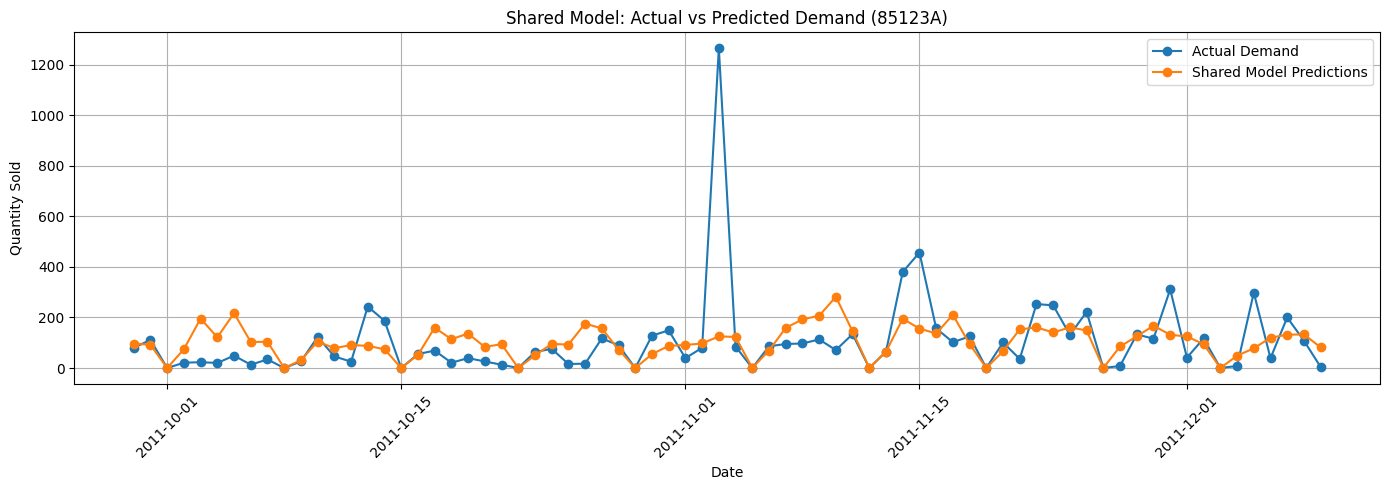

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    selected_test['Date'],
    selected_test['Demand'],
    label='Actual Demand',
    marker='o'
)

plt.plot(
    selected_test['Date'],
    selected_predictions,
    label='Shared Model Predictions',
    marker='o'
)

plt.title('Shared Model: Actual vs Predicted Demand (85123A)')
plt.xlabel('Date')
plt.ylabel('Quantity Sold')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [44]:
def predict_demand(stock_code, days=7):

    history = multi_product_daily[
        multi_product_daily['StockCode'].astype(str) == str(stock_code)
    ].sort_values('Date')['Demand'].tolist()

    dates = pd.date_range(
        start=multi_product_daily['Date'].max() + pd.Timedelta(days=1),
        periods=days
    )

    product_id = product_encoder.transform([str(stock_code)])[0]

    predictions = []

    for date in dates:

        features_input = pd.DataFrame([{
            'Product_ID': product_id,
            'Month': date.month,
            'DayOfWeek': date.dayofweek,
            'Lag1': history[-1],
            'Lag7': history[-7],
            'Roll7': np.mean(history[-7:]),
            'Roll14': np.mean(history[-14:])
        }])

        prediction = max(0, shared_model.predict(features_input)[0])

        predictions.append(round(prediction, 2))
        history.append(prediction)

    return pd.DataFrame({
        'Date': dates,
        'StockCode': stock_code,
        'Predicted_Demand': predictions
    })


# Test with our selected product
forecast = predict_demand('85123A', 7)

print(forecast)

        Date StockCode  Predicted_Demand
0 2011-12-10    85123A              0.00
1 2011-12-11    85123A             21.90
2 2011-12-12    85123A            169.02
3 2011-12-13    85123A            113.48
4 2011-12-14    85123A            125.86
5 2011-12-15    85123A            108.50
6 2011-12-16    85123A             70.64


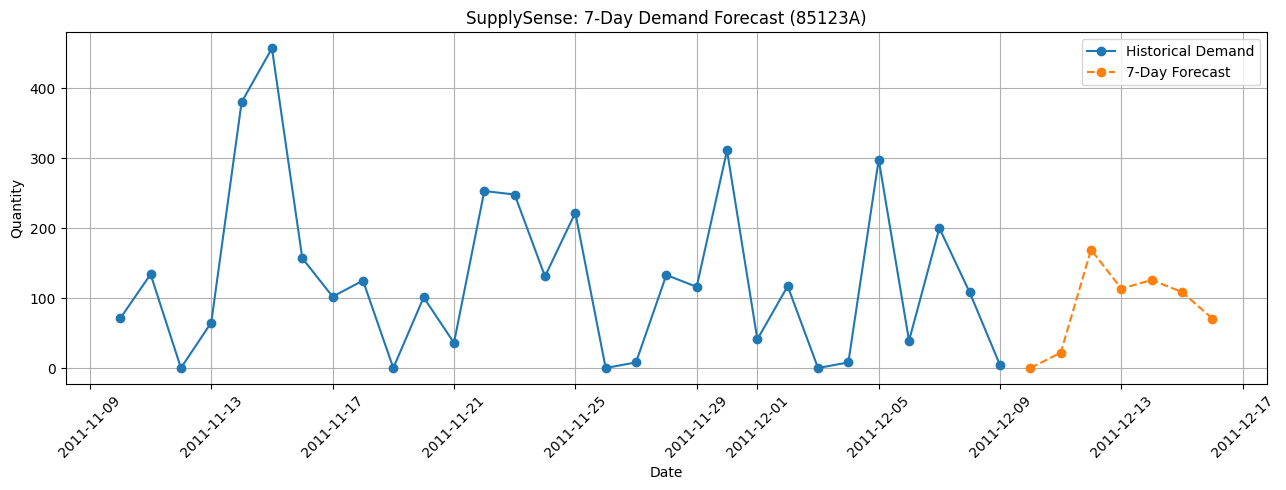

In [45]:
import matplotlib.pyplot as plt

historical = multi_product_daily[
    multi_product_daily['StockCode'].astype(str) == '85123A'
].tail(30)

plt.figure(figsize=(13, 5))

plt.plot(
    historical['Date'],
    historical['Demand'],
    marker='o',
    label='Historical Demand'
)

plt.plot(
    forecast['Date'],
    forecast['Predicted_Demand'],
    marker='o',
    linestyle='--',
    label='7-Day Forecast'
)

plt.title('SupplySense: 7-Day Demand Forecast (85123A)')
plt.xlabel('Date')
plt.ylabel('Quantity')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [46]:
# Create product catalogue
product_catalog = df[['StockCode', 'Description']].dropna().copy()

product_catalog['StockCode'] = product_catalog['StockCode'].astype(str)

product_catalog = (
    product_catalog.groupby('StockCode')['Description']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])
    .reset_index()
)

# Keep only products supported by our trained model
valid_codes = set(multi_product_daily['StockCode'].astype(str).unique())

product_catalog = product_catalog[
    product_catalog['StockCode'].isin(valid_codes)
]

print("Total products:", len(product_catalog))
print(product_catalog.head(10))

Total products: 3922
  StockCode                   Description
0     10002   INFLATABLE POLITICAL GLOBE 
1     10080      GROOVY CACTUS INFLATABLE
2     10120                  DOGGY RUBBER
3    10123C         HEARTS WRAPPING TAPE 
4    10124A   SPOTS ON RED BOOKCOVER TAPE
5    10124G      ARMY CAMO BOOKCOVER TAPE
6     10125       MINI FUNKY DESIGN TAPES
7     10133  COLOURING PENCILS BROWN TUBE
8     10135  COLOURING PENCILS BROWN TUBE
9     11001   ASSTD DESIGN RACING CAR PEN


In [47]:
import joblib
import os

model_bundle = {
    'model': shared_model,
    'product_encoder': product_encoder,
    'product_catalog': product_catalog,
    'historical_data': multi_product_daily,
    'features': features,
    'last_date': multi_product_daily['Date'].max()
}

joblib.dump(
    model_bundle,
    'supplysense_model.pkl',
    compress=3
)

print("Model exported successfully!")
print("File size:", round(os.path.getsize('supplysense_model.pkl') / (1024 * 1024), 2), "MB")

Model exported successfully!
File size: 27.14 MB


In [48]:
from google.colab import files

files.download('supplysense_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
import joblib
import os

# Make the historical data more compact
compact_history = multi_product_daily.copy()

compact_history['StockCode'] = compact_history['StockCode'].astype('category')
compact_history['Demand'] = compact_history['Demand'].astype('int32')

# Rebuild the model bundle
model_bundle['historical_data'] = compact_history

# Save with maximum compression
joblib.dump(
    model_bundle,
    'supplysense_model_compressed.pkl',
    compress=9
)

size = os.path.getsize('supplysense_model_compressed.pkl') / (1024 * 1024)

print(f"New file size: {size:.2f} MB")

New file size: 24.63 MB


In [50]:
from google.colab import files
files.download('supplysense_model_compressed.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>